In [1]:
!rm -rf clone && git clone https://github.com/ferit-osirv/lab2 clone && cp -a clone/. .

Cloning into 'clone'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 37 (delta 4), reused 13 (delta 2), pack-reused 14 (from 1)
Receiving objects: 100% (37/37), 6.06 MiB | 36.92 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [2]:
!find . -name "apple.jpg"

./images/apple.jpg
./clone/images/apple.jpg


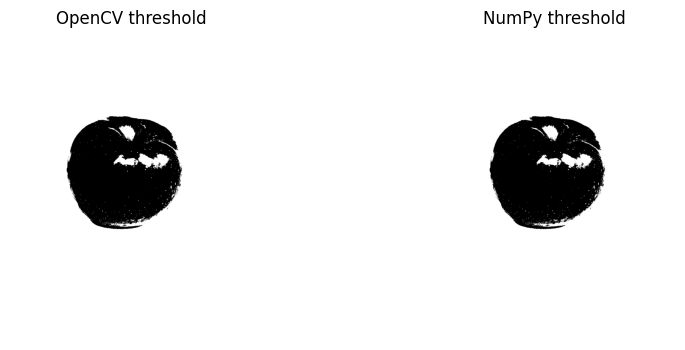

In [3]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread('./images/apple.jpg', cv.IMREAD_GRAYSCALE)

# OpenCV
threshold_value = 127
_, thresholded_cv = cv.threshold(
    img, threshold_value, 255, cv.THRESH_BINARY
)

# NumPy
thresholded_numpy = np.where(
    img > threshold_value, 255, 0
).astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(thresholded_cv, cmap='gray')
plt.title('OpenCV threshold')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(thresholded_numpy, cmap='gray')
plt.title('NumPy threshold')
plt.axis('off')

plt.show()

Optimalni threshold: 165.0


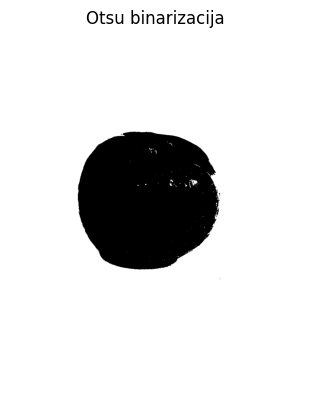

In [4]:
otsu_threshold, otsu_image = cv.threshold(
    img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
)

print("Optimalni threshold:", otsu_threshold)

plt.imshow(otsu_image, cmap='gray')
plt.title('Otsu binarizacija')
plt.axis('off')
plt.show()

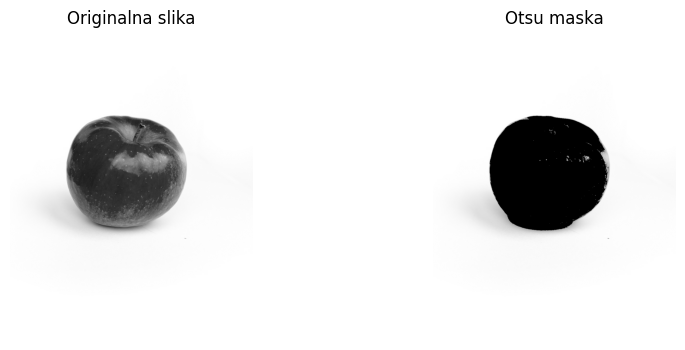

In [5]:
mask = otsu_image

img_thresholded = cv.bitwise_and(
    img, img, mask=mask
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_thresholded, cmap='gray')
plt.title('Otsu maska')
plt.axis('off')

plt.show()